1.Introduction

2.Import Libraries

In [ ]:

import torch
import torchvision
import torchvision.datasets as datasets
import torchvision.transforms as transforms
import numpy as np
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader, random_split
from torch import nn
import torch.optim as optim

print("All libraries imported successfully!")
print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)


All libraries imported successfully!
PyTorch version: 2.14.1+cu130
Torchvision version: 0.29.1+cu130


3.Load CIFAR-10 Dataset

In [ ]:
train_dataset = datasets.CIFAR10(
    root='./data',
    train=True,
    download=True
)

test_dataset = datasets.CIFAR10(
    root='./data',
    train=False,
    download=True
)


print("Training dataset size:", len(train_dataset))
print("Testing dataset size:", len(test_dataset))


100%|██████████| 170M/170M [40:41<00:00, 69.8kB/s]


Training dataset size: 50000
Testing dataset size: 10000


4.Data Preprocessing

In [ ]:


transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])


train_dataset = datasets.CIFAR10(
    root='./data',
    train=True,
    download=False,
    transform=transform
)

test_dataset = datasets.CIFAR10(
    root='./data',
    train=False,
    download=False,
    transform=transform
)

image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Label:", label)
print("Number of training images:", len(train_dataset))
print("Number of testing images:", len(test_dataset))


Image shape: torch.Size([3, 32, 32])
Label: 6
Number of training images: 50000
Number of testing images: 10000


5.Training and Validation Split

In [ ]:



from torch.utils.data import random_split


torch.manual_seed(42)

train_size = 45000
validation_size = 5000

train_subset, validation_subset = random_split(
    train_dataset,
    [train_size, validation_size]
)


print("Training images:", len(train_subset))
print("Validation images:", len(validation_subset))
print("Testing images:", len(test_dataset))


Training images: 45000
Validation images: 5000
Testing images: 10000


6.MLP Model Architecture

In [ ]:



class MLP(nn.Module):
    def __init__(self):
        super(MLP, self).__init__()

        self.flatten = nn.Flatten()

        self.fc1 = nn.Linear(3072, 512)
        self.relu1 = nn.ReLU()

        self.fc2 = nn.Linear(512, 256)
        self.relu2 = nn.ReLU()

        self.fc3 = nn.Linear(256, 10)

    def forward(self, x):
        x = self.flatten(x)

        x = self.fc1(x)
        x = self.relu1(x)

        x = self.fc2(x)
        x = self.relu2(x)

        x = self.fc3(x)

        return x




model = MLP()

print(model)


MLP(
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (fc1): Linear(in_features=3072, out_features=512, bias=True)
  (relu1): ReLU()
  (fc2): Linear(in_features=512, out_features=256, bias=True)
  (relu2): ReLU()
  (fc3): Linear(in_features=256, out_features=10, bias=True)
)


7.Loss Function and Optimiser

In [ ]:



criterion = nn.CrossEntropyLoss()


optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function:", criterion)
print("Optimiser:", optimizer)


Loss function: CrossEntropyLoss()
Optimiser: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


8.Model Training

In [ ]:



batch_size = 128

train_loader = DataLoader(
    train_subset,
    batch_size=batch_size,
    shuffle=True
)

validation_loader = DataLoader(
    validation_subset,
    batch_size=batch_size,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(validation_loader))


Training batches: 352
Validation batches: 40


In [ ]:



device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = model.to(device)

print("Using device:", device)



num_epochs = 10

train_losses = []
validation_losses = []


for epoch in range(num_epochs):

    model.train()
    running_train_loss = 0.0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_train_loss += loss.item() * images.size(0)

    epoch_train_loss = running_train_loss / len(train_subset)
    train_losses.append(epoch_train_loss)


    model.eval()
    running_validation_loss = 0.0

    with torch.no_grad():

        for images, labels in validation_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            running_validation_loss += loss.item() * images.size(0)

    epoch_validation_loss = running_validation_loss / len(validation_subset)
    validation_losses.append(epoch_validation_loss)

    print(
        f"Epoch [{epoch+1}/{num_epochs}] "
        f"Training Loss: {epoch_train_loss:.4f} "
        f"Validation Loss: {epoch_validation_loss:.4f}"
    )

print("Training completed!")


Using device: cuda
Epoch [1/10] Training Loss: 1.6509 Validation Loss: 1.5139
Epoch [2/10] Training Loss: 1.4329 Validation Loss: 1.4481
Epoch [3/10] Training Loss: 1.3331 Validation Loss: 1.4163
Epoch [4/10] Training Loss: 1.2413 Validation Loss: 1.4210
Epoch [5/10] Training Loss: 1.1562 Validation Loss: 1.3922
Epoch [6/10] Training Loss: 1.0789 Validation Loss: 1.4316
Epoch [7/10] Training Loss: 1.0100 Validation Loss: 1.4447
Epoch [8/10] Training Loss: 0.9382 Validation Loss: 1.4507
Epoch [9/10] Training Loss: 0.8730 Validation Loss: 1.5276
Epoch [10/10] Training Loss: 0.8002 Validation Loss: 1.5685
Training completed!


9.Model Evaluation

In [ ]:


test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False
)

model.eval()

correct = 0
total = 0
running_test_loss = 0.0

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        loss = criterion(outputs, labels)
        running_test_loss += loss.item() * images.size(0)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

test_accuracy = 100 * correct / total
test_loss = running_test_loss / total

print("Test Accuracy: {:.2f}%".format(test_accuracy))
print("Test Loss: {:.4f}".format(test_loss))
print("Correct Predictions:", correct)
print("Incorrect Predictions:", total - correct)


Test Accuracy: 53.25%
Test Loss: 1.5648
Correct Predictions: 5325
Incorrect Predictions: 4675


In [ ]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

training_accuracy = 100 * correct / total

print(f"Training Accuracy: {training_accuracy:.2f}%")

Training Accuracy: 76.21%


10.Visualisation of Training and Validation Loss

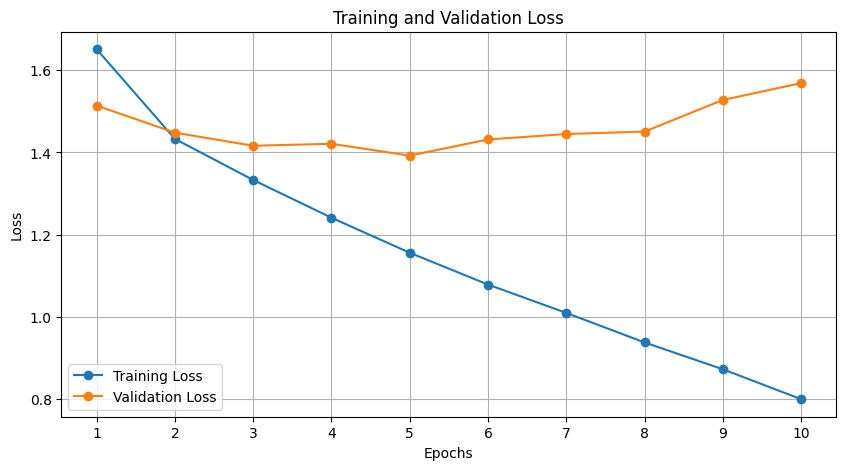

In [ ]:



epochs = range(1, num_epochs + 1)

plt.figure(figsize=(10, 5))

plt.plot(
    epochs,
    train_losses,
    marker='o',
    label='Training Loss'
)

plt.plot(
    epochs,
    validation_losses,
    marker='o',
    label='Validation Loss'
)

plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.legend()
plt.grid(True)

plt.xticks(epochs)

plt.show()


11.Results and Observations

## Results and Observations

### 1. Model Architecture
- Model: Multi-Layer Perceptron (MLP)
- Input features: 3,072
- First hidden layer: 512 neurons (ReLU)
- Second hidden layer: 256 neurons (ReLU)
- Output layer: 10 neurons
- Total trainable Linear layers: 3

### 2. Training Configuration
- Dataset: CIFAR-10
- Training samples: 45,000
- Validation samples: 5,000
- Testing samples: 10,000
- Epochs: 10
- Batch size: 128
- Optimiser: Adam
- Learning rate: 0.001
- Loss function: CrossEntropyLoss

### 3. Model Performance
- Final training loss: 0.8002
- Final validation loss: 1.5685
- Test loss: 1.5648
- Test accuracy: 53.25%
- Correct predictions: 5325
- Incorrect predictions: 4675

### 4. Observations
The MLP model achieved a test accuracy of 53.25% on the CIFAR-10 test dataset. Out of 10,000 test images, the model correctly classified 5,325 images and incorrectly classified 4,675 images.

The final training loss was 0.8002, while the validation loss was 1.5685. The test loss was 1.5648.

The difference between training and validation loss suggests that the model may be overfitting the training data. Although the model learned useful image features, its ability to generalise to unseen images could be improved.

Further experiments could investigate regularisation techniques, dropout, and different hidden-layer configurations.